# Математички методи за машинско учење 2025/2026
## Домаћи задатак број 4

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 04Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [1]:
import numpy as np
import scipy as sp
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

**Задатак 1.** Нека је дата матрица $A\in\mathcal{M}_{m\times n}.$ Декомпозиција пуног ранга изражава матрицу $A,$ ${\rm rang}(A)=r\leq\min\{m,n\}$ у облику производа $A=XY,$ $X\in\mathcal{M}_{m\times r},$ $Y\in\mathcal{M}_{r\times n},$ ${\rm rang}(X)={\rm rang}(Y)=r.$ 

**а)** Која од матрица $X$ и $Y$ обезбеђује базу простора врста, а која простора колона матрице $A?$ Како све можемо одредити базне векторе левог и десног језгра матрице $A?$ Због чега ортогоналне базе у овом поступку имају предност?

(5 поена)

Kolone matrice $X$ čine bazu prostora kolona matrice $A$, jer svaka kolona matrice $A$ je linearna kombinacija kolona matrice $X$.
Slično, vrste matrice $Y$ čine bazu prostora vrsta matrice $A$, jer svaka vrsta matrice $A$ je linearna kombinacija vrsta matrice $Y$.

Desno jezgro:
  $$
  N(A) = \{ v \in \mathbb{R}^n\ |\ Av = \theta \}.
  $$
  Pošto je $A = XY$, imamo $Av = X(Yv)$.  
  Ako je $Av = 0$, mora biti $Yv = 0$ (jer $X$ ima rang $r$).  
  Dakle:
  $$
  N(A) = N(Y).
  $$
  Bazne vektore desnog jezgra dobijamo rešavanjem sistema $Yv = 0$ (npr. pomoću Gausove eliminacije).

Levo jezgro:
  $$
  N(A^T) = \{ u \in \mathbb{R}^m\ |\ A^T u = \theta \}.
  $$
  Pošto je $A^T = Y^T X^T$, imamo $A^T u = Y^T (X^T u)$.  
  Ako je $A^T u = 0$, mora biti $X^T u = 0$ (jer $Y^T$ ima rang $r$).  
  Dakle:
  $$
  N(A^T) = N(X^T).
  $$
  Bazne vektore levog jezgra dobijamo rešavanjem sistema $X^T u = 0$ (npr. pomoću Gausove eliminacije).

Korišćenje ortogonalnih baza ima sledeće prednosti:
- obezbeđuju numeričku stabilnost u računanju,
- pojednostavljuju projekcije i izračunavanje koordinata i
- minimizuju akumulaciju grešaka kod numeričkih metoda.

**б)** Написати функцију `full_rank_decomp(A, tol=1e-10)` која рачуна `X` и `Y` факторе, али и аутоматски одређује ранг `r` матрице `A`. За декомпозицију користити `scipy.linalg.lu` која враћа `P, L, U`.
Ранг `r` одредити на основу матрице `U` и задате толеранције `tol` (број значајних пивота).
Функција треба да врати три вредности: `X`, `Y` и израчунати ранг `r`.
  
У текстуалној ћелији објаснити како се из `P, L, U` формирају `X` и `Y` и како се дефинише ранг преко матрице `U`.

**Ограничење:** Забрањено коришћење Python петљи.

(10 поена)

Za matricu $A$ dobijamo faktorizaciju  
$$A = P L U$$ 
gde je $P$ permutaciona matrica, $L$ donje trougaona matrica sa jedinicama na dijagonali, a $U$ gornje trougaona matrica.
 
Pošto želimo dekompoziciju punog ranga $A = X Y$, uzimamo prvih $r$ kolona iz $P L$ i prvih $r$ redova iz $U$.

Rang matrice $A$ se određuje na osnovu broja nenultih pivota u $U$.  
Praktično, uzimamo dijagonalu matrice $U$ i brojimo elemente koji su veći od zadate tolerancije $\mathrm{tol}$.  
To daje broj značajnih pivota, odnosno rang matrice $A$.

In [2]:
def full_rank_decomp(A, tol=1e-10):
    P, L, U = sp.linalg.lu(A)
    diag_U = np.abs(np.diag(U))
    r = np.sum(diag_U > tol)
    X = P @ L[:, :r]
    Y = U[:r, :]
    return X, Y, r

**в)** Применити написану функцију `full_rank_decomp(A)` на генерисане матрице из наредне кодне ћелије. Упоредити добијени нумерички ранг са теоријским рангом који је коришћен при генерисању. Објаснити геометријско значење ранга $r$ у контексту димензионалности података (2D и 3D).  

(5 поена)

In [3]:
bazna_matrica_r1 = np.array([[2., 1]]) # ранг 1
tezine_r1 = np.random.uniform(-10, 10, (100, 1)) 
A_r1 = tezine_r1 @ bazna_matrica_r1

bazna_matrica_r2 = np.array([[1, 0, 1],[0., 1, 1]]) # ранг 2
tezine_r2 = np.random.randn(100, 2) 
A_r2 = tezine_r2 @ bazna_matrica_r2

print(f"Матрица A_r1 генерисана: димензије {A_r1.shape}, теоријски ранг 1")
print(f"Матрица A_r2 генерисана: димензије {A_r2.shape}, теоријски ранг 2")

Матрица A_r1 генерисана: димензије (100, 2), теоријски ранг 1
Матрица A_r2 генерисана: димензије (100, 3), теоријски ранг 2


In [4]:
X1, Y1, r1 = full_rank_decomp(A_r1)
X2, Y2, r2 = full_rank_decomp(A_r2)

print("rang(A_r1)=", r1)
print("rang(A_r2)=", r2)

rang(A_r1)= 1
rang(A_r2)= 2


Dobijamo iste numeričke i teorijske rangove matrica, što znači da je postupak ispravan.

Rang matrice možemo posmatrati kao meru dimenzionalnosti prostora u kojem se podaci nalaze. Kada redove ili kolone matrice posmatramo kao vektore, rang nam govori koliko ih je zaista linearno nezavisno, odnosno u kolikom potprostoru oni leže. 

Na primer, matrica $A_{r1}$ ima rang 1, što znači da svih 100 dvodimenzionalnih tačaka koje ona sadrži zapravo leže na jednoj pravoj u ravni. Iako podaci imaju dve koordinate, njihova stvarna dimenzionalnost je samo 1. 

Slično tome, matrica $A_{r2}$ ima rang 2 što znači da se tačke u trodimenzionalnom prostoru sa tri koordinate zapravo nalaze u jednoj ravni, pa je njihova efektivna dimenzionalnost 2.

**г)** **За матрицу `A_r1` (2D тачке):** Нацртати оригиналне тачке и правац који дефинише база простора врста.

**За матрицу `A_r2` (3D тачке):** Користећи 3D приказ, нацртати тачке и раван коју разапињу врсте матрице $A$.

Како чињеница да је $r < n$ омогућава ефикасније складиштење података? 

Израчунати број елемената потребних за чување оригиналне матрице $A$ у односу на матрице $X$ и $Y$.

(4+6+3+2 поена)

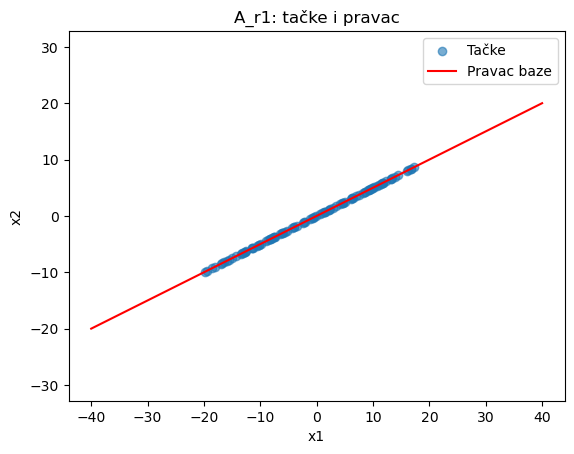

In [5]:
plt.scatter(A_r1[:,0], A_r1[:,1], alpha=0.6, label="Tačke")

# baza prostora je vektor [2, 1]
v = np.array([2,1])
t = np.linspace(-20,20,100)
plt.plot(t*v[0], t*v[1], 'r', label="Pravac baze")

plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.axis("equal")
plt.title("A_r1: tačke i pravac")
plt.show()

In [6]:
import ipywidgets as widgets
from ipywidgets import interact

# # bazni vektori su [1, 0, 1] i [0, 1, 1]
u = np.array([1,0,1])
v = np.array([0,1,1])
s = np.linspace(-5,5,10)
t = np.linspace(-5,5,10)
S,T = np.meshgrid(s,t)
plane = S[:,:,None]*u + T[:,:,None]*v

def plot_with_view(elev=30, azim=30):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(A_r2[:,0], A_r2[:,1], A_r2[:,2], alpha=0.6, label="Tačke")
    ax.plot_surface(plane[:,:,0], plane[:,:,1], plane[:,:,2], alpha=0.3, color='red')
    
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title("A_r2: tačke i ravan")
    plt.show()

interact(plot_with_view, elev=widgets.IntSlider(min=0, max=90, step=5, value=30),
                           azim=widgets.IntSlider(min=0, max=180, step=10, value=30))

interactive(children=(IntSlider(value=30, description='elev', max=90, step=5), IntSlider(value=30, description…

<function __main__.plot_with_view(elev=30, azim=30)>

Ako je rang matrice manji od broja kolona ($r < n$), to znači da se podaci zapravo nalaze u nižedimenzionalnom potprostoru. Umesto da čuvamo celu matricu $A$, možemo da je predstavimo kao proizvod $A = X Y$, gde su matrice $X$ i $Y$ mnogo manjih dimenzija. Time se smanjuje broj elemenata koje treba zapamtiti.

Za matricu $A$ dimenzija $m \times n$, broj elemenata je
$$
m \cdot n.
$$
Za faktore $X$ i $Y$:
$$
X \in \mathcal{M}_{m \times r}, \quad Y \in \mathcal{M}_{r \times n},
$$
pa je ukupan broj elemenata
$$
m \cdot r + r \cdot n.
$$

Konkretno, za prethodne primere:

- Za matricu $A_{r1}$ dimenzija $100 \times 2$ i rang $r=1$:
Original:  $100 \cdot 2 = 200, \qquad$
Faktori: $100 \cdot 1 + 1 \cdot 2 = 102$

- Za matricu $A_{r2}$ dimenzija $100 \times 3$ i rang $r=2$:
Original: $100 \cdot 3 = 300, \qquad$
Faktori: $100 \cdot 2 + 2 \cdot 3 = 206$

Vidimo da se može postići značajna ušteda memorije.

**д)** Познато је да су простор врста $\mathcal{R}(A^T)$ и језгро $\mathcal{N}(A)$ ортогонални комплементи.

Користећи функцију `scipy.linalg.null_space`, одредити базу језгра матрице $A_{r2}$. 
Програмски (скаларним производом) потврдити ортогоналност између базе простора врста и базе језгра.

Додати вектор језгра на 3D график. Прокоментарисати његов положај у односу на раван простора врста.

(10 поена)

In [7]:
N = sp.linalg.null_space(A_r2)
print("Baza jezgra A_r2:\n", N)

Baza jezgra A_r2:
 [[-0.57735027]
 [-0.57735027]
 [ 0.57735027]]


In [8]:
kernel_vector = N[:, 0]
dot_products = bazna_matrica_r2 @ kernel_vector
print("Skalarni proizvodi:", dot_products)

Skalarni proizvodi: [1.11022302e-16 1.11022302e-16]


Vidimo da su skalarni proizvodi praktično $0$, što znači da su vektori baze prostora vrsta i baze jezgra međusobno ortogonalni.

In [9]:
kernel_vector_scaled = kernel_vector * 3 # povecavamo intenzitet vektora da bi se lakse video na grafiku

In [10]:
def plot_with_view(elev=30, azim=30):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(A_r2[:,0], A_r2[:,1], A_r2[:,2], alpha=0.6, label="Tačke")
    ax.plot_surface(plane[:,:,0], plane[:,:,1], plane[:,:,2], alpha=0.3, color='red')
    ax.quiver(0, 0, 0, kernel_vector_scaled[0], kernel_vector_scaled[1], kernel_vector_scaled[2], color='blue', linewidth=2, label="Vektor jezgra")

    # kljucno je da se postave iste razmere na svim osama kako bi vektor stvarno izgledao normalno na ravan
    ax.set_xlim([-8, 8])
    ax.set_ylim([-8, 8])
    ax.set_zlim([-8, 8])
    
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title("A_r2: tačke i ravan")
    plt.show()

interact(plot_with_view, elev=widgets.IntSlider(min=0, max=90, step=5, value=30),
                           azim=widgets.IntSlider(min=0, max=180, step=10, value=30))

interactive(children=(IntSlider(value=30, description='elev', max=90, step=5), IntSlider(value=30, description…

<function __main__.plot_with_view(elev=30, azim=30)>

Vektor je normalan na ravan koju razapinju vektori vrsta matrice $A_{r2}$ što je i očekivano.

***

**Задатак 2.** У машинском учењу често користимо LU декомпозицију блок матрица - декомпозиција матрице на производ блок доње троугаоне и блок горње троугаоне матрице.  

Посматрајмо матрицу $ M $ подељену на блокове:
$$
M =
\begin{bmatrix}
A & B \\
C & D
\end{bmatrix},
$$
где је $ A$ квадратна регуларна матрица.

**а)** Показати (матричним множењем) да се $M$ може факторисати као:
$$M =L_BU_B=\begin{bmatrix}
I & 0 \\
CA^{-1} & I
\end{bmatrix}
\begin{bmatrix}
A & B \\
0 & S
\end{bmatrix},
$$
где је $S$ тзв. Шуров комплемент матрице $A$ у односу на $M.$

Експлицитно извести израз за $S,$
$$
S = D - CA^{-1}B.
$$

(5 поена)

Proizvod blok matrica $L_B U_B$:

Prvi blok (gornji levi):
$$
I \cdot A + 0 \cdot 0 = A
$$

Drugi blok (gornji desni):
$$
I \cdot B + 0 \cdot S = B
$$

Treći blok (donji levi):
$$
(CA^{-1})A + I \cdot 0 = C
$$

Četvrti blok (donji desni):
$$
(CA^{-1})B + I \cdot S = C A^{-1} B + S
$$

Dakle, ceo proizvod je
$$
\begin{bmatrix}
A & B \\
C & C A^{-1} B + S
\end{bmatrix}
$$

Da bi ovaj rezultat bio jednak originalnoj matrici $M$, mora da važi
$$
C A^{-1} B + S = D
$$

Iz toga eksplicitno dobijamo
$$
S = D - C A^{-1} B
$$

**б)** Посматрајмо блок матрицу  
$M = \begin{bmatrix} A & B \\ C & D \end{bmatrix}$  
где је $A$ инвертибилна квадратна матрица.

Имплементирати функцију која за дату блок матрицу израчунава Шуров комплемент матрице $A$ у односу на $M.$ 

(5 поена)

Prvi način - eksplicitno računanje inverzne matrice $A^{-1}$:

In [11]:
def schur_complement(M, block_A_size):
    A = M[:block_A_size, :block_A_size]
    B = M[:block_A_size, block_A_size:]
    C = M[block_A_size:, :block_A_size]
    D = M[block_A_size:, block_A_size:]
    
    A_inv = sp.linalg.inv(A)           
    S = D - C @ (A_inv @ B)     
    return S

Drugi način (optimizovaniji i numerički stabilniji) - ne računamo matricu $A^{-1}$ eksplicitno, već čitav proizvod $A^{-1} B$ računamo pomoću funkcije `sp.linalg.solve(A, B)`

In [12]:
def schur_complement_optimized(M, block_A_size):
    A = M[:block_A_size, :block_A_size]
    B = M[:block_A_size, block_A_size:]
    C = M[block_A_size:, :block_A_size]
    D = M[block_A_size:, block_A_size:]
    
    # solve(A, B) resava sistem AX = B, tj. X = A^{-1}B
    S = D - C @ sp.linalg.solve(A, B)
    return S

**в)** Показати програмски да важи:  
$$\det(M) = \det(A)\,\det(S).$$
Применити овај концепт на блок матрицу димензија $10 \times 10$ подељену на четири блока $5 \times 5$.

(5 поена)

In [13]:
A = np.random.randint(1, 10, (5,5))

# obezbedimo da A bude invertibilna
while sp.linalg.det(A) == 0:
    A = np.random.randint(1, 10, (5,5))

B = np.random.randint(1, 10, (5,5))
C = np.random.randint(1, 10, (5,5))
D = np.random.randint(1, 10, (5,5))

M = np.block([[A, B],
              [C, D]])

S = schur_complement_optimized(M, 5)

det_M = sp.linalg.det(M)
det_A = sp.linalg.det(A)
det_S = sp.linalg.det(S)

print("det_M: ", det_M)
print("det_A*det_S: ", det_A * det_S)
print("Razlika: ", det_M - det_A * det_S)

det_M:  -51214578.00000007
det_A*det_S:  -51214578.0
Razlika:  -6.705522537231445e-08


Vidimo da jednakost važi, odnosno da je razlika praktično $0$.

**г)** Написати функцију `block_lu_step(M, block_size)` која за задату матрицу $M$ и величину горњег левог блока $A:$

- издваја блокове користећи slicing,   
- враћа матрицу $M$ трансформисану у блок горње  троугаону форму $U_B,$ као резултат блок LU процеса.  

Решење мора бити скалабилно за било коју димензију блокова.

(5 поена)

In [14]:
def block_lu_step(M, block_size):
    A = M[:block_size, :block_size]
    B = M[:block_size, block_size:]
    C = M[block_size:, :block_size]
    D = M[block_size:, block_size:]
    
    det_A = sp.linalg.det(A)
    if abs(det_A) < 1e-12:
        raise ValueError("Blok A nije regularna matrica.")
    
    S = D - C @ sp.linalg.solve(A, B)

    U = np.block([
        [A, B],
        [np.zeros_like(C), S]
    ])
    
    return U

***

**Задатак 3.** Размотримо матрицу која је нумерички "опасна" за LU декомпозицију без пивотирања:
$$ A_\varepsilon = \begin{bmatrix} \varepsilon & 1 \\ 1 & 1 \end{bmatrix},$$
gde je $\varepsilon < \varepsilon_{\text{mach}}.$ 

**а)** Ручно (или симболички) израчунати $L$ и $U=\begin{bmatrix}u_{00}&u_{01}\\u_{10}&u_{11}\end{bmatrix}$ факторе без пивотирања.  
Шта се дешава са елементом $u_{11}$ у аритметици са покретним зарезом? Спроведите експлицитне кораке израчунавања резултата на примеру Numpy низа $$A_\varepsilon = \begin{bmatrix} 10^{-16} & 1 \\ 1 & 1 \end{bmatrix}.$$

(10 поена)

Prvi pivot je $$u_{00} = \varepsilon$$

Eliminacioni faktor je $$l_{10} = \frac{1}{\varepsilon}$$

Prva vrsta matrice $U$ je jednaka prvoj vrsti matrice $A$. Element $u_{10}$ je jednak $0$. Element $u_{11}$ je jednak $A_{11} - l_{10} \cdot u_{01} = 1 - \frac{1}{\varepsilon}\cdot 1$. Zbog toga je matrica $U$ jednaka:
$$
U =
\begin{bmatrix}
u_{00} & u_{01} \\
0      & u_{11}
\end{bmatrix}
=
\begin{bmatrix}
\varepsilon & 1 \\
0 & 1 - \frac{1}{\varepsilon}\cdot 1
\end{bmatrix}
=
\begin{bmatrix}
\varepsilon & 1 \\
0 & 1 - \frac{1}{\varepsilon}
\end{bmatrix}
$$

Dakle:
$$
L =
\begin{bmatrix}
1 & 0 \\
\frac{1}{\varepsilon} & 1
\end{bmatrix},
\qquad
U =
\begin{bmatrix}
\varepsilon & 1 \\
0 & 1 - \frac{1}{\varepsilon}
\end{bmatrix}
$$


U aritmetici sa pokretnim zarezom, ako je $\varepsilon$  veoma mali broj (npr. manji od mašinske tačnosti) onda je $\frac{1}{\varepsilon }=10^{16}$.
Dakle:
$u_{11}\approx 1-10^{16}\approx -10^{16}$

Problem je što u računaru, zbog ograničene preciznosti, vrednost $\varepsilon$  se praktično tretira kao nula. To znači da se pivot $u_{00}=\varepsilon$  numerički „gubi“, a eliminacioni faktor $l_{10}=1/\varepsilon$ postaje ogroman, tako da dobijamo nestabilne rezultate. To možemo videti i sledećim Python kodom.

In [21]:
eps = np.finfo(float).eps
print("Mašinsko epsilon: ", eps)

Mašinsko epsilon:  2.220446049250313e-16


In [23]:
eps = 1e-16 # manje od mašinskog epsilon
A = np.array([[eps, 1.0],
              [1.0, 1.0]])

u00 = A[0,0]
u01 = A[0,1]
l10 = A[1,0] / u00
u11 = A[1,1] - l10 * u01

print("u00=", u00)
print("u01=", u01)
print("l10=", l10)
print("u11=", u11)

L = np.array([[1.0, 0.0],
              [l10, 1.0]])

U = np.array([[u00, u01],
              [0.0, u11]])

LU = L @ U
print("A=\n", A)
print("L @ U =\n", LU)
print("Razlika A - L@U =\n", A - LU)

u00= 1e-16
u01= 1.0
l10= 1e+16
u11= -1e+16
A=
 [[0. 1.]
 [1. 1.]]
L @ U =
 [[0. 1.]
 [1. 0.]]
Razlika A - L@U =
 [[0. 0.]
 [0. 1.]]


Dobijeni rezultati pokazuju da faktorizacija nije stabilna, a samim tim ni ispravna.

**б)** Користећи `scipy.linalg.lu`, израчунати факторе са пивотирањем.  
Упоредити грешку репродукције $\|A - PLU\|_F$ за овај и претходни поступак. Објаснити зашто је замена редова (пивотирање) неопходна за стабилност код матрица са малим елементима на главној дијагонали. 

(10 поена) 

In [25]:
err_no_pivot = sp.linalg.norm(A - LU, 'fro')

P, L, U = sp.linalg.lu(A)
PLU = P @ L @ U
err_pivot = sp.linalg.norm(A - PLU, 'fro')

print("Greška bez pivotiranja:", err_no_pivot)
print("Greška sa pivotiranjem:", err_pivot)

Greška bez pivotiranja: 1.0
Greška sa pivotiranjem: 0.0


Vidimo da kod postupka LU faktorizacije sa pivotiranjem nemamo grešku, dok kod postupka bez pivotiranja imamo grešku $1.0$.

Pivotiranje je neophodno za stabilnost zato što ako pivot na dijagonali ima vrednost manju od mašinske epsilon, računanje eliminacionog faktora $l_{10}=A_{10}/u_{00}$ daje ogroman broj. To dovodi do numeričke nestabilnosti i gubitka tačnosti. Zamena redova bira veći element kao pivot (ovde $1$ umesto $10^{-16}$), čime se izbegava deljenje brojem bliskog nuli i omogućava stabilnost algoritma.

**в)** У Numpy-у, за $\varepsilon = 10^{-20},$ решити систем  
$$A_\varepsilon x = [1, 2]^T $$  
на два начина:  
- Користећи сопствену имплементацију експлицитних корака без пивотирања.  
- Користећи `scipy.linalg.solve` (која користи пивотирање).

(10 поена)

Koristimo postupak rešavanja sistema jednačina pomoću $LU$ dekompozicije opisanog [ovde](https://courses.physics.illinois.edu/cs357/sp2020/notes/ref-9-linsys.html).

$A x = b \;\;\Rightarrow\;\; L U x = b$

$$
L y = b \quad \text{(forward substitution to find $y$)}
$$

$$
U x = y \quad \text{(backward substitution to find $x$)}
$$

$$
\begin{bmatrix}
1 & 0 \\
\ell_{10} & 1
\end{bmatrix}
\begin{bmatrix}
y_0 \\
y_1
\end{bmatrix}
=
\begin{bmatrix}
y_0 \\
\ell_{10}y_0 + y_1
\end{bmatrix}
=
\begin{bmatrix}
b_0 \\
b_1
\end{bmatrix}
$$

$$
\begin{bmatrix}
u_{00} & u_{01} \\
0 & u_{11}
\end{bmatrix}
\begin{bmatrix}
x_0 \\
x_1
\end{bmatrix}
=
\begin{bmatrix}
u_{00}x_0 + u_{01}x_1 \\
u_{11}x_1
\end{bmatrix}
=
\begin{bmatrix}
y_0 \\
y_1
\end{bmatrix}
$$

In [27]:
eps = 1e-20
A = np.array([[eps, 1.0],
              [1.0, 1.0]])
b = np.array([1.0, 2.0])

u00 = A[0,0]
u01 = A[0,1]
l10 = A[1,0] / u00
u11 = A[1,1] - l10 * u01

L = np.array([[1.0, 0.0],
              [l10, 1.0]])
U = np.array([[u00, u01],
              [0.0, u11]])

y0 = b[0]
y1 = b[1] - l10*y0
y = np.array([y0, y1])

x1 = y[1] / U[1,1]
x0 = (y[0] - U[0,1]*x1) / U[0,0]
x_no_pivot = np.array([x0, x1])

x_pivot = sp.linalg.solve(A, b)

print("Rešenje bez pivotiranja:", x_no_pivot)
print("Rešenje sa pivotiranjem:", x_pivot)

Rešenje bez pivotiranja: [0. 1.]
Rešenje sa pivotiranjem: [1. 1.]


**г)** Упоредити релативну грешку  
$$\|A x_{\text{izračunato}} - b\|.$$
Повезати резултат са задатком о катастрофалном поништавању са претходног домаћег.  

(5 поена)

In [29]:
res_no_pivot = A @ x_no_pivot - b
res_pivot = A @ x_pivot - b

err_no_pivot_abs = sp.linalg.norm(res_no_pivot)
err_pivot_abs = sp.linalg.norm(res_pivot)

err_no_pivot_rel = err_no_pivot_abs / sp.linalg.norm(b)
err_pivot_rel = err_pivot_abs / sp.linalg.norm(b)

print("Apsolutna greška bez pivotiranja:", err_no_pivot_abs)
print("Relativna greška bez pivotiranja:", err_no_pivot_rel)

print("Apsolutna greška sa pivotiranjem:", err_pivot_abs)
print("Relativna greška sa pivotiranjem:", err_pivot_rel)

Apsolutna greška bez pivotiranja: 1.0
Relativna greška bez pivotiranja: 0.4472135954999579
Apsolutna greška sa pivotiranjem: 0.0
Relativna greška sa pivotiranjem: 0.0


U numeričkoj analizi, katastrofalno poništavanje je fenomen pri kojem oduzimanje dobrih aproksimacija dve bliske vrednosti može dati veoma lošu aproksimaciju razlike njihovih originalnih vrednosti.

Ovde se javlja sličan numerički problem: zbog malog pivota $\varepsilon$ , faktor $1/\varepsilon$  postaje ogroman. Pri računanju $u_{11}=1-(1/\varepsilon )\cdot 1$, od malog broja ($1$) se oduzima ogroman broj ($10^{20}$), pa se gubi veliki broj značajnih cifara. To dovodi do numeričke nestabilnosti, koja se manifestuje slično kao katastrofalno poništavanje.

***

**Задатак 4.**
У пракси се често сусрећемо са матрицама које су регуларне, али су осетљиве – мале промене у подацима доводе до огромних грешака у решењу. 

**а)** Користећи функцију `np.vander`, креирати Вандермондову матрицу $V$ димензија $10 \times 10$ над низом од 10 еквидистантних тачака из интервала $[1, 2]$. 
1. Извршити LU декомпозицију $PV = LU$. Приказати дијагоналне елементе (пивоте) матрице $U$. Шта примећујете код последњих неколико пивота?
2. Дефинисати тачно решење $x_{true} = \text{np.ones}(10)$ и израчунати десну страну $b = V x_{true}$.
3. Решити систем $Vx = b$ помоћу `np.linalg.solve`. Израчунати Фробенијусову норму грешке $\|x - x_{true}\|_F$.

(5 поена)

**б)** Симулирајмо малу грешку у мерењу података (шум). 
1. Креирати вектор слободних чланова са додатком белог шума $b_{noise} = b + \epsilon$, где је $\epsilon$ насумичан вектор јако мале норме (нпр. $10^{-8}$).
2. Поново решити систем $Vx_{noise} = b_{noise}$ и израчунати грешку $\|x_{noise} - x_{true}\|_F$.
3. Упоредити норму шума $\|\epsilon\|_F$ и норму грешке у решењу. Колико пута се грешка увећала?

(10 поена)

**в)** Уводимо регуларизовану матрицу $V_{\lambda} = V + \lambda I.$
1. Написати функцију која за низ вредности $\lambda = [10^{-1}, 10^{-3}, 10^{-6}, 10^{-9}, 0]$ израчунава LU декомпозицију и решава систем са шумом $(V + \lambda I)x_{\lambda} = b_{noise}$.
2. За свако $\lambda$ израчунати:
   - Вредност најмањег пивота матрице $U$ (по апсолутној вредности).
   - Грешку решења $\|x_{\lambda} - x_{true}\|_F$.
3. Нацртати два графика (у логаритамској скали): 
   - Зависност најмањег пивота од $\lambda$.
   - Зависност грешке решења од $\lambda$.
   
(10 поена)

**г)**  
На основу добијених графика објаснити шта се дешава са стабилношћу система када је $\lambda=0$. Како додавање малог $\lambda$ утиче на вредност пивота и зашто то спречава експлозију грешке? Повезати ово са стабилизацијом нумеричких израчунавања кроз спречавање дељења јако малим бројевима.

(5 поена)

***

**Задатак 5.** У претходном домаћем сте користили K-means за компресију слике. Сада ћемо то упоредити са апроксимацијом ниског ранга која се ослања на декомпозицију пуног ранга матрице слике.

Активирати доњи код којим се учитава слика (grayscale) као матрица $A.$  
И дефинише функција којом се израчунава најбоља апроксимација помоћу декомпозиције пуног ранга $A_k = X_k Y_k$ на основу задатог параметра $k.$ Параметар $k$ је унапред дефинисан ранг матрица фактора $X_k$ и $Y_k.$

In [15]:
import scipy.datasets as scd

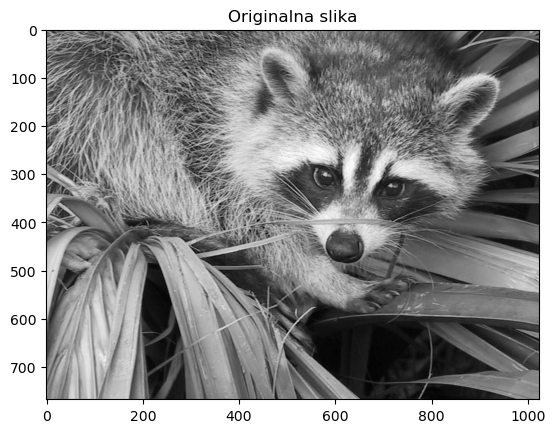

In [16]:
rakun=scd.face()
sk_vredn=rakun/255
A = sk_vredn @ [0.2126, 0.7152, 0.0722]
A.shape
plt.imshow(A, cmap="gray");
plt.title("Originalna slika");

In [17]:
def naj_aproks(A,k):
    X,S,Y=sp.linalg.svd(A)
    A_k=(X*S)[:,:k]@Y[:k,:] #деккомпозиција пуног ранга апроксимационе матрице A_k
    return(A_k)

**а)** Нацртати график зависности грешке апроксимације  
$$\|A - A_k\|_F$$  
од ранга $k$ (за $k\in\{1, 5, 10, 20, 50\}$).  

(5 поена)

**б)** Упоредити број параметара потребан за чување слике код:
- K-means сегментације (из прошлог домаћег),
- Апроксимације ниског ранга $A_k=X_k Y_k.$

Који метод боље чува текстуру, а који регије (боје)?  Можете да проверите резултате функционисања оба поступка на додатним сликама према свом избору. Бирајте неке које су природнијег садржаја наспрам слика са једним објектом у фокусу.

(10 поена)

***

**Задатак 6.** У обради слика, суперпиксели представљају групе пиксела које замењују класичну правоугаону мрежу. Овде ћемо слику посматрати као велику блок матрицу и спровести основну суперпиксел декомпозицију користећи векторизацију.

**а)** 
Написати функцију `image_to_blocks(img, k)` која трансформише grayscale слику димензија $H \times W$ у 4D низ димензија $(H/k, W/k, k, k)$, где сваки елемент $(i, j)$ представља блок величине $k \times k$. Такође, написати инверзну функцију `blocks_to_image(blocks)` која враћа блокове у оригинални 2D формат користећи `np.block` или паметно препакивање. 

(Напомена: Користити слику ракуна и исећи је тако да су димензије дељиве са $k=10$.)  

(10 поена)

**б)**  За сваки блок израчунати средњи интензитет пиксела и $(x, y)$ координате центра блока у оригиналној слици. Резултат треба да буде матрица карактеристика $F$ димензија $(N_{blocks} \times 3)$. Све прорачуне извршити векторизовано (користећи `np.mean` по одговарајућим осама).  

(10 поена)

**в)**  Применити K-means кластеризацију над матрицом $F$. Реконструисати слику тако што ће сваки блок бити замењен средњим интензитетом који дефинише центар припадајућег кластера. Приказати резултат сегментације.  

(10 поена)

***